# 07 — Intergenerational Mobility (Núñez–Miranda 2010)

Python replication of `MirandaNunez.Rmd` (first stage, TSTSLS elasticity, rank-rank, multiple imputation). Logic in `source/mobility.py`, plots in `source/figures.py`. Reference outputs in `/home/choroy/Downloads/Problem Set 1/Outputs/`.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from utils import load_root
ROOT = load_root()
import source.mobility as mob
from source.figures import plot_rank_sector, plot_mi_sensitivity, save_fig
OUTPUTFIG = ROOT / 'figures/p1'
OUTPUTDATA = ROOT / 'data/processed/mobility'
OUTPUTDATA.mkdir(parents=True, exist_ok=True)
%load_ext autoreload
%autoreload 2

[utils] Project root loaded successfully: /home/choroy/Documents/doctorado/S4/ENECO894/problem-set


## 1. First stage (Table A)

Historic earnings equations (CASEN 1987, 1990): `log y` on education dummies + age profile. Weights: none. SE: HC1.

In [2]:
samples = {}
for y in [1987, 1990]:
    samples[str(y)] = mob.build_sample(pd.read_stata(ROOT / f'data/CASEN/Casen{y}.dta', convert_categoricals=False), y)
    print(y, len(samples[str(y)]))
model_cols = ['dP', 'dS', 'dT', 'dU', 'edad', 'Age2']
for y in ['1987', '1990']:
    d = samples[y]
    X = mob.design_matrix(d, model_cols)
    b, V, _, n = mob.ols(d['Y'].to_numpy(), X)
    print(y, dict(zip(['c'] + model_cols, np.round(b, 4))))

1987 18769
1990 20387
1987 {'c': np.float64(8.1609), 'dP': np.float64(0.2538), 'dS': np.float64(0.7564), 'dT': np.float64(1.0638), 'dU': np.float64(1.7927), 'edad': np.float64(0.0777), 'Age2': np.float64(-0.0008)}
1990 {'c': np.float64(9.1366), 'dP': np.float64(0.2132), 'dS': np.float64(0.6315), 'dT': np.float64(0.9426), 'dU': np.float64(1.4808), 'edad': np.float64(0.0657), 'Age2': np.float64(-0.0006)}


## 2. TSTSLS elasticity (Table 1)

Second stage on CASEN 2006 sons with Murphy–Topel SE (independence between surveys). Compares with R `tabla_1_resultados.csv`.

In [3]:
hijos = mob.recode_2006(pd.read_stata(ROOT / 'data/CASEN/Casen2006.dta', convert_categoricals=False))
print('sons', len(hijos))
t1 = pd.concat([mob.two_step_elasticity(samples, hijos, ['dP','dS','dT','dU'], None),
                mob.two_step_elasticity(samples, hijos, ['dP','dS','dT','dU'], ['Empleador','Self','Servicio'])], ignore_index=True)
display(t1.round(4))
ref = pd.read_csv('/home/choroy/Downloads/Problem Set 1/Outputs/tabla_1_resultados.csv')
print('max |elasticidad diff|:', (t1.elasticidad - ref.elasticidad).abs().max())
print('max |EE_MT diff|:', (t1.EE_MT - ref.EE_MT).abs().max())
t1.to_csv(OUTPUTDATA / 'tabla_1.csv', index=False)

sons 11178


,grupo,modelo,elasticidad,EE_MT,EE_condicional,N
0,25-30,Education,0.7480,0.0419,0.0403,3017
1,31-35,Education,0.9024,0.0407,0.0382,3550
2,36-40,Education,0.8350,0.0380,0.0362,4611
3,25-40,Education,0.8334,0.0240,0.0224,11178
4,31-40,Education,0.8615,0.0281,0.0266,8161
5,25-30,Education and occupation,0.4706,0.0356,0.0341,3017
6,31-35,Education and occupation,0.6697,0.0334,0.0312,3550
7,36-40,Education and occupation,0.6693,0.0351,0.0325,4611
8,25-40,Education and occupation,0.6139,0.0211,0.0193,11178
9,31-40,Education and occupation,0.6695,0.0246,0.0228,8161


max |elasticidad diff|: 6.725946577468278e-08
max |EE_MT diff|: 2.1824266699388417e-09


## 3. Rank-rank (Tables 1B/1C) + Figure 1

Percentile ranks within age group (average ties). Sectors: formal = contributes (o29 1–5), informal = affiliated w/o contribution or unaffiliated (o29 6–7). Common ranks before splitting.

,grupo,modelo,sector,constante,EE_constante,beta,EE_beta,rho_spearman,beta_con_edad,EE_beta_con_edad,N
9,25-40,Education,Total,33.749,0.523,0.325,0.009,0.319,0.327,0.009,11178
10,25-40,Education,Formal,35.537,0.589,0.320,0.010,0.329,0.322,0.010,8241
11,25-40,Education,Informal,30.836,1.077,0.295,0.021,0.257,0.298,0.021,2823
24,25-40,Education and occupation,Total,33.906,0.506,0.322,0.009,0.320,0.324,0.009,11178
25,25-40,Education and occupation,Formal,36.338,0.558,0.313,0.010,0.331,0.314,0.010,8241
26,25-40,Education and occupation,Informal,28.000,1.113,0.329,0.020,0.286,0.340,0.021,2823


saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/figures/p1/rank_sector.pdf


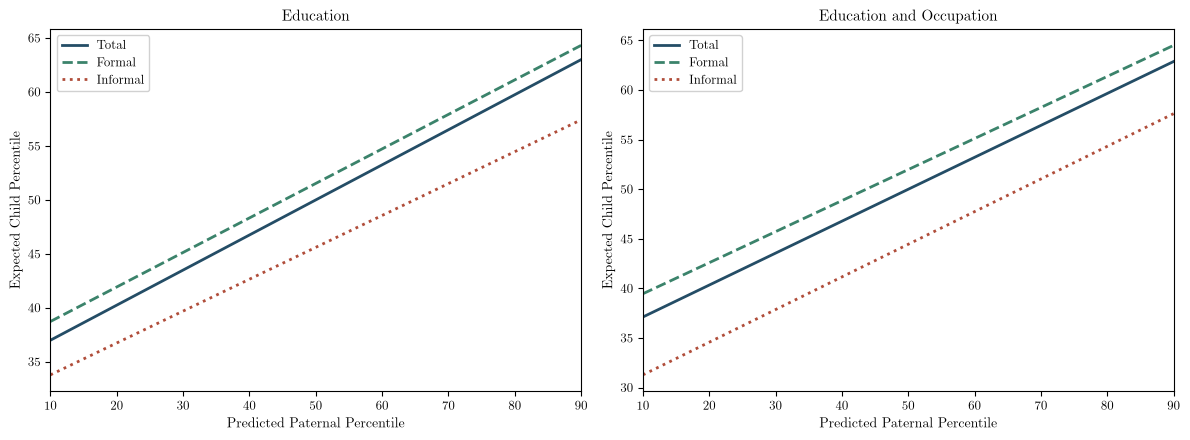

In [4]:
rr = pd.concat([mob.rank_rank(samples, hijos, ['dP','dS','dT','dU'], None),
              mob.rank_rank(samples, hijos, ['dP','dS','dT','dU'], ['Empleador','Self','Servicio'])], ignore_index=True)
display(rr[rr.grupo == '25-40'].round(3))
rr.to_csv(OUTPUTDATA / 'tabla_rank.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_rank_sector(rr, fig, axes)
plt.tight_layout()
save_fig(OUTPUTFIG / 'rank_sector.pdf', fig)
plt.show()

## 4. Multiple imputation (Tables 1D/1E) + Figure 2

Bivariate lognormal + affiliation logit. M=100, rho in (0, 0.3, 0.6), seed 17102026. Same DGP as R; RNG engine differs so values match within MCSE, not exactly.

    rho criterio_hijo combinacion   beta     EE  N_medio
0   0.0    Afiliacion         F-F  0.171  0.019  4191.28
1   0.0    Afiliacion         F-I  0.249  0.072   462.44
2   0.0    Afiliacion         I-F  0.117  0.034  1538.72
3   0.0    Afiliacion         I-I  0.150  0.092   305.56
4   0.0    Cotizacion         F-F  0.167  0.020  3681.78
5   0.0    Cotizacion         F-I  0.220  0.050   971.94
6   0.0    Cotizacion         I-F  0.118  0.037  1263.22
7   0.0    Cotizacion         I-I  0.133  0.064   581.06
8   0.3    Afiliacion         F-F  0.371  0.018  4192.49
9   0.3    Afiliacion         F-I  0.529  0.058   460.16
10  0.3    Afiliacion         I-F  0.316  0.032  1537.51
11  0.3    Afiliacion         I-I  0.460  0.075   307.84
12  0.3    Cotizacion         F-F  0.354  0.019  3687.20
13  0.3    Cotizacion         F-I  0.493  0.042   965.45
14  0.3    Cotizacion         I-F  0.297  0.036  1257.80
15  0.3    Cotizacion         I-I  0.428  0.053   587.55
16  0.6    Afiliacion         F

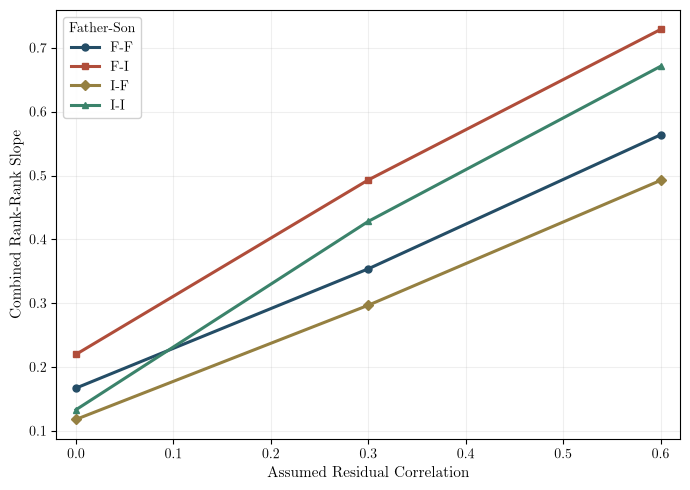

In [5]:
sim, mires, miind = mob.multiple_imputation(samples, hijos, ['dP','dS','dT','dU'], ['Empleador','Self','Servicio'], seed=17102026, M=100, rhos=(0.0, 0.3, 0.6))
sim.to_csv(OUTPUTDATA / 'simulacion_rank.csv', index=False)
mires.to_csv(OUTPUTDATA / 'mi_resumen.csv', index=False)
miind.to_csv(OUTPUTDATA / 'mi_individual.csv', index=False)
print(mires[['rho','criterio_hijo','combinacion','beta','EE','N_medio']].round(3).to_string())
fig, ax = plt.subplots(figsize=(7, 5))
plot_mi_sensitivity(mires, fig, ax)
plt.tight_layout()
save_fig(OUTPUTFIG / 'sensibilidad_MI.pdf', fig)
plt.show()